# 데이터 분할

- 머신러닝 모델의 성능을 정확하게 평가하기 위해서는 훈련에 사용하지 않은 테스트 세트를 통해 평가해야함

- 평가를 위한 별도의 데이터를 준비하거나 준비된 데이터 중에 일부를 떼어 테스트 세트로 준비

- 훈련 : 테스트 비율은 70 ~ 80 : 20 ~ 30
    - 반드시 정해져 있는 것은 아니며 연구자의 임의로 조절 가능함
    - 전체 데이터가 아주 크고 모든 데이터 패턴을 잘 담아내기만 한다면 테스트 데이터는 1%만 사용해도 충분할 수 있음

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("./data/Fish.csv")

In [3]:
df = df.loc[df["Species"].isin(["Bream", "Smelt"]), ["Species", "Weight", "Length2"]]

In [4]:
le = LabelEncoder()
df["label"] = le.fit_transform(df["Species"])

In [5]:
df.head()

,Species,Weight,Length2,label
0,Bream,242.0,25.4,0
1,Bream,290.0,26.3,0
2,Bream,340.0,26.5,0
3,Bream,363.0,29.0,0
4,Bream,430.0,29.0,0


In [7]:
df.tail()

,Species,Weight,Length2,label
154,Smelt,12.2,12.2,1
155,Smelt,13.4,12.4,1
156,Smelt,12.2,13.0,1
157,Smelt,19.7,14.3,1
158,Smelt,19.9,15.0,1


In [6]:
df.shape

(49, 4)

## 샘플링 편향

- 훈련 세트에 도미 데이터와 빙어 데이터가 골고루 들어가 있지 않다면 올바르게 분류할 수 없음
    - 예) 빙어 없이 모델 훈련이 이루어진다면 어떤 데이터를 빙어로 분류해야할지 알 수 없음
 
- 데이터가 골고루 섞여있지 않으면 샘플링이 한쪽으로 치우쳤다는 의미로 샘플링 편향(sampling bias)라고 부름

### train_test_split()

- 전달되는 리스트나 배열을 섞은 후 비율에 맞게 훈련 세트와 테스트 세트로 나누어 주는 함수

- 매개변수
    - 첫 번째 매개변수 : 피처 데이터 세트
      
    - 두 번째 매개변수 : 레이블 데이터 세트
 
    - test_size
        - 전체 데이터에서 테스트 세트 크기를 얼마로 샘플링 할 것인가를 결정
        - 초기값은 0.25
     
    - train_size
        - 전체 데이터에서 학습용 데이터 세트 크기를 얼마로 샘플링 할 것인가를 결정
        - 일반적으로는 test_size를 활용
     
    - shuffle
        - 데이터를 분리하기 전에 데이터를 미리 섞을지를 결정
        - 초기값은 True
        - 데이터를 분산시켜서 좀 더 효율적인 학습 및 테스트 데이터 세트를 만드는 데 사용
     
    - random_state
        - 매번 코드를 실행할 때마다 다른 결과가 나온다면 정확하게 모델을 평가할 수 없고 모델 최적화에 어려움이 있음
        - 난수를 생성할 때 특정한 규칙으로 생성해서 매번 같은 결과가 나오게 통제할 수 있음
     
    - stratify
        - 무작위로 데이터를 섞으면 샘플링 편향이 일어날 수 있기 때문에 기존 데이터의 비율과 같은 비율로 데이터를 나눌 수 있도록 할 수 있음
     
- 반환값
    - 튜플 형태
    - 훈련 데이터의 피처, 테스트 데이터의 피처, 훈련 데이터의 레이블, 테스트 데이터의 레이블 이 순서대로 반환

In [59]:
x_train, x_test, y_train, y_test = train_test_split(df[["Length2", "Weight"]], df["label"],
                                                    test_size = 0.25, stratify = df["label"],
                                                    random_state = 23)

In [60]:
print(len(x_train), len(x_test), len(y_train), len(y_test))

36 13 36 13


In [61]:
y_test

155    1
27     0
157    1
31     0
25     0
7      0
148    1
9      0
19     0
13     0
12     0
151    1
26     0
Name: label, dtype: int32

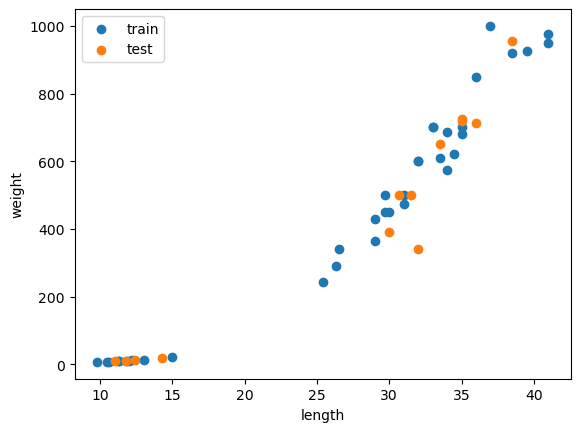

In [62]:
plt.figure()

plt.scatter(x_train["Length2"], x_train["Weight"], label = "train")
plt.scatter(x_test["Length2"], x_test["Weight"], label = "test")
plt.legend()
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

# 모델 훈련

In [63]:
knn = KNeighborsClassifier()

In [64]:
knn.fit(x_train, y_train)

KNeighborsClassifier()

# 모델 평가

In [65]:
knn.score(x_test, y_test)

1.0

# 모델 최적화

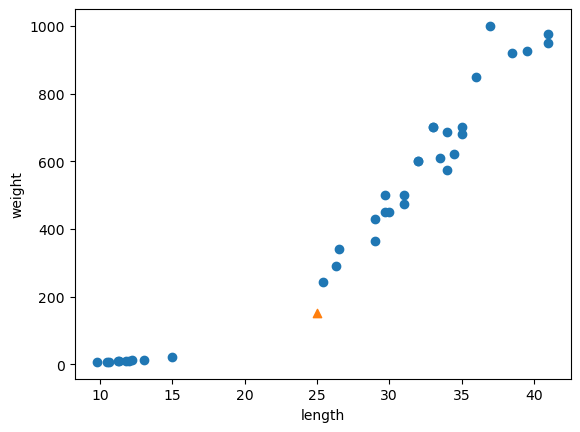

In [66]:
plt.figure()

plt.scatter(x_train.iloc[:, 0], x_train.iloc[:, 1])
plt.scatter(25, 150, marker = "^")
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

In [67]:
# 길이 25, 무게 150의 생선에 대한 예측
knn.predict([[25, 150]])

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


array([1])

In [68]:
le.inverse_transform([1])

array(['Smelt'], dtype=object)

- kneighbors()
    - 이웃까지의 거리와 이웃 샘플의 인덱스를 반환

In [69]:
dist, idx = knn.kneighbors([[25, 150]])

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [70]:
x_train.iloc[idx.flatten()]

,Length2,Weight
0,25.4,242.0
158,15.0,19.9
156,13.0,12.2
154,12.2,12.2
1,26.3,290.0


In [71]:
y_train.iloc[idx.flatten()]

0      0
158    1
156    1
154    1
1      0
Name: label, dtype: int32

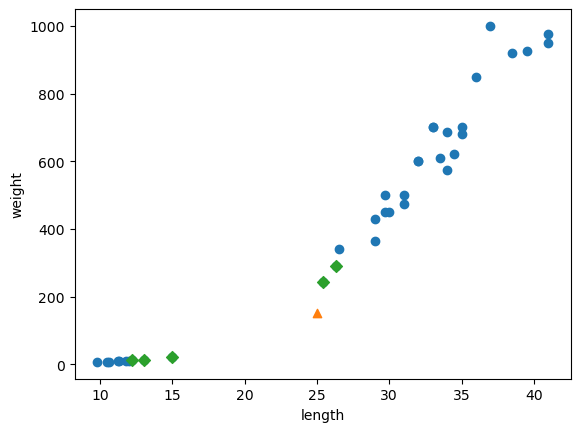

In [72]:
plt.figure()

plt.scatter(x_train.iloc[:, 0], x_train.iloc[:, 1])
plt.scatter(25, 150, marker = "^")
plt.scatter(x_train.iloc[idx.flatten(), 0], x_train.iloc[idx.flatten(), 1], marker = "D")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

In [73]:
dist

array([[ 92.00086956, 130.48375378, 138.32150953, 138.39320793,
        140.00603558]])

- x축은 범위가 좁고, y축은 범위가 넓기 때문에 y축으로 조금만 벌어져도 큰 값으로 거리가 계산됨

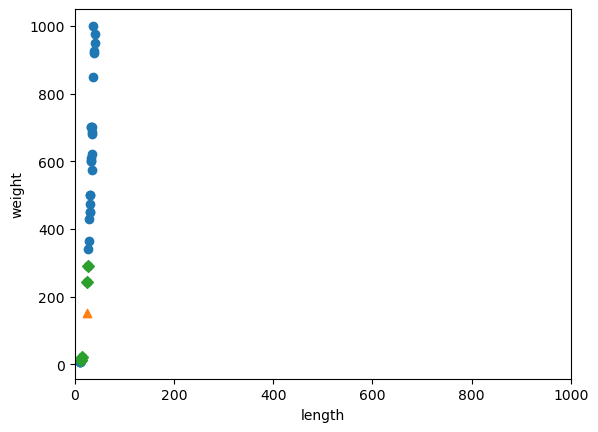

In [74]:
plt.figure()

plt.scatter(x_train.iloc[:, 0], x_train.iloc[:, 1])
plt.scatter(25, 150, marker = "^")
plt.scatter(x_train.iloc[idx.flatten(), 0], x_train.iloc[idx.flatten(), 1], marker = "D")

plt.xlim(0, 1000)
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

- 시각화 자료를 참고하면 현재 데이터에서 생선의 길이는 모델이 값을 예측하는데에 거의 사용되지 않고 있음
    - 두 독립변수의 단위가 다르기 때문에
 
- knn은 특히 데이터 간 거리가 모델 성능에 영향을 많이 주는 특성이 있음
    - 각 독립변수의 단위가 다르면 올바른 예측이 어려울 가능성이 높음
 
- 각 독립변수의 단위를 일정한 기준으로 맞춰 주는 작업을 스케일링(scaling) 이라고 함

## 스케일링

- 스탠다드 스케일링(standard scaling)
    - 각 피처값이 평균에서 표준편차의 몇 배만큼 떨어져있는지를 나타내 데이터의 단위와 관계없이 동일한 조건으로 비교할 수 있게 변환
        - 분산 : 데이터에서 평균을 뺀 값을 모두 제곱한 다음 평균을 계산
        - 표준편차 : 분산의 제곱근. 데이터가 분산된 정도
     
    - 평균이 0이고 분산이 1인 가우시안 정규 분포를 가진 값으로 변환
        - 몇몇 알고리즘에서는 데이터가 가우시안 정규 분포를 가지고 있다고 가정하고 구현하기 때문에 스탠다드 스케일링이 예측 성능 향상에 중요한 요소가 될 수 있음
            - 예) 서포트 벡터 머신, 선형 회귀, 로지스틱 회귀
         
    - 계산식
        - (특성값 - 평균) / 표준편차
     
- MinMaxScaler
    - 데이터 값을 0과 1사이의 범위 값으로 변환
        - 음수 값이 있으면 -1에서 1 사이의 값으로 변환
     
- 학습 데이터와 테스트 데이터의 스케일링 변환 시 유의점
    - scaler 객체를 이용해 데이터 스케일링 변환 시 사용 메서드
        - fit()
            - 데이터 변환을 위한 기준 정보 설정
            - 예) 데이터 세트의 최댓값/최솟값 설정 등
     
        - transform()
            - fit()으로 설정된 정보를 이용해 데이터를 변환
     
        - fit_transform()
            - fit() 과 transform() 을 한 번에 적용
         
    - **학습 데이터로 fit() 이 적용된 스케일링 기준 정보를 그대로 테스트 데이터에 적용해야함**
        - 테스트 데이터로 다시 새로운 스케일링 기준 정보를 만들게 되면 학습 데이터와 테스트 데이터의 스케일링 기준 정보가 서로 달라지기 때문에 올바른 예측 결과를 도출하지 못함

In [75]:
# 스탠다드 스케일링 객체 생성
ss = StandardScaler()

In [76]:
scaled_x_train = ss.fit_transform(x_train)

In [77]:
scaled_x_train

array([[-0.05462992, -0.33822937],
       [ 0.78120782,  0.75936249],
       [ 0.63370704,  0.48496453],
       [-0.07429669, -0.49067268],
       [ 0.87954167,  1.21669243],
       [ 1.22371015,  1.4453574 ],
       [-1.50013753, -1.34466012],
       [ 1.37121092,  1.59780071],
       [ 0.26003841,  0.14958924],
       [ 0.48620626,  0.45447586],
       [-1.48047076, -1.34496501],
       [ 0.38787241,  0.07336758],
       [ 0.97787552,  1.67402237],
       [ 0.48620626,  0.45447586],
       [-0.16279715, -0.63701826],
       [-1.46080399, -1.33764773],
       [ 0.28953856, -0.00285408],
       [ 0.19120471, -0.26810544],
       [ 0.78120782,  0.69838516],
       [ 0.26003841, -0.00285408],
       [-1.62797153, -1.3519774 ],
       [-1.69680523, -1.35441649],
       [ 0.73204089,  0.51545319],
       [ 0.38787241,  0.14958924],
       [ 1.37121092,  1.52157906],
       [-1.55913784, -1.34496501],
       [-1.3821369 , -1.33764773],
       [ 0.68287396,  0.37825421],
       [-1.61813815,

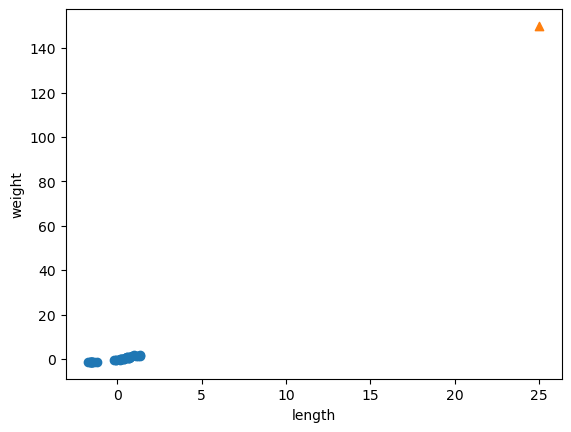

In [78]:
# 스케일링된 데이터 시각화
plt.figure()

plt.scatter(scaled_x_train[:, 0], scaled_x_train[:, 1])
plt.scatter(25, 150, marker = "^")
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

- 값의 스케일이 달라졌기 때문에 테스트 데이터도 스케일링 해줘야 함

In [79]:
scaled_data = ss.transform([[25, 150]])

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [80]:
scaled_data

array([[-0.20213069, -0.91751396]])

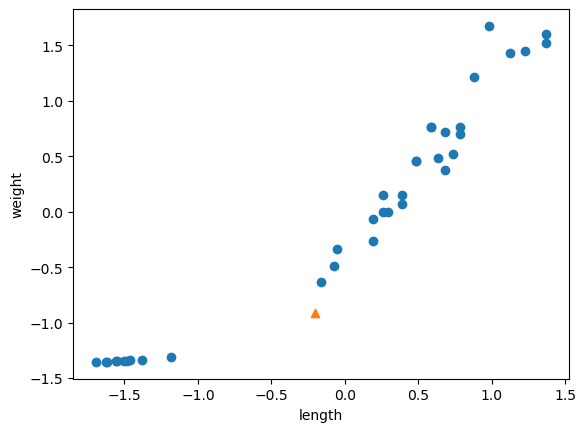

In [81]:
plt.figure()

plt.scatter(scaled_x_train[:, 0], scaled_x_train[:, 1])
plt.scatter(scaled_data[0, 0], scaled_data[0, 1], marker = "^")
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

In [82]:
# 테스트 데이터 스케일링
scaled_x_test = ss.transform(x_test)

In [83]:
# 스케일링된 데이터로 다시 모델 훈련
knn = KNeighborsClassifier()

In [84]:
knn.fit(scaled_x_train, y_train)

KNeighborsClassifier()

In [85]:
knn.score(scaled_x_test, y_test)

1.0

In [86]:
# 문제의 데이터 예측
knn.predict(scaled_data)

array([0])

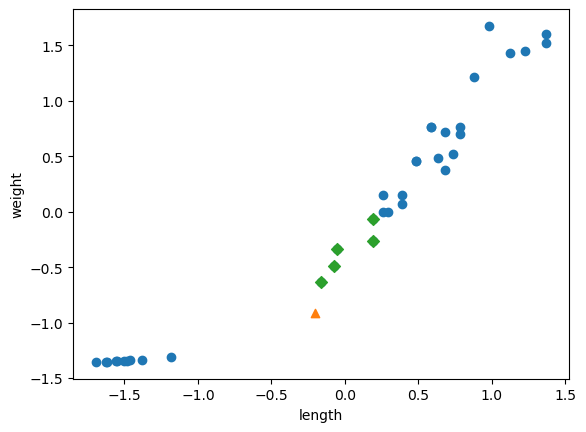

In [88]:
# 시각화
dist, idx = knn.kneighbors(scaled_data)

plt.figure()

plt.scatter(scaled_x_train[:, 0], scaled_x_train[:, 1])
plt.scatter(scaled_data[0, 0], scaled_data[0, 1], marker = "^")
plt.scatter(scaled_x_train[idx.flatten(), 0], scaled_x_train[idx.flatten(), 1], marker = "D")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()